# 06 · Pay policy, matching and a dispatch simulation

**Question.** For each trip, what premium above the floor should we offer, to maximize expected
margin while keeping waits, acceptance and driver earnings at least where they are today? And does
the policy still hold up when we replay a real day of requests with drivers moving around the city?

**Part A: the policy.** Using the acceptance curves from phase 5 (the hierarchical model, with its
uncertainty), choose a premium for each cell = zone cluster × hour band × difficulty quintile, by
mixed-integer linear programming under constraints C1–C5. The policy is **fitted on January–March
2025 trips and evaluated on April–June 2025**, scored against the *planted truth*, which the
optimizer never saw.

**Part B: the simulation.** Replay every real Brooklyn request on two days of June 2025 (a Tuesday
and a Saturday) through a dispatch simulator: simulated drivers, real requests. Compare today's pay
with the policy, and greedy matching with batched optimal matching.

In [1]:
import time

import numpy as np
import pandas as pd
from scipy.special import expit

from ridepay import accept, config, data, dispatch, features, plots, policy, simulate
from ridepay.records import show_verdict, write_metrics

SOURCE = data.source()
FAST = SOURCE != "real"          # CI smoke run on the synthetic city: fewer draws, seeds and calibration steps
con = data.connect()
ALL = data.months()
FIT = [m for m in ALL if "2025-01" <= m <= "2025-03"] or ALL[-6:-3]
HELD = [m for m in ALL if "2025-04" <= m <= "2025-06"] or ALL[-3:]
post = np.load(data.interim_dir() / "derived" / "accept_posterior.npz")
segments = [tuple(s.split("|")) for s in post["segments"]]
seg_index = {s: i for i, s in enumerate(segments)}
truth_tab = data.load_table("accept_truth").set_index(["cluster_name", "band"])
print(f"fit on {FIT}, evaluate on {HELD}; {len(segments)} segments; {post['beta'].shape[0]} posterior draws")


def prepare(months):
    df, info = features.trip_frame(months, con)
    f = simulate.difficulty_features(df, info)
    df = df.join(f)
    df = df[[(c, b) in seg_index for c, b in zip(df["cluster_name"], df["band"])]].copy()
    df["seg"] = [seg_index[(c, b)] for c, b in zip(df["cluster_name"], df["band"])]
    return df, info


fit_df, info = prepare(FIT)
held_df, _ = prepare(HELD)
gamma_mean = post["gamma"].mean(axis=0)
fit_df["d_hat"] = fit_df[accept.FEATURES].to_numpy() @ gamma_mean
edges = np.quantile(fit_df["d_hat"], [0.2, 0.4, 0.6, 0.8])           # quintile edges from the fit window only
for d in (fit_df, held_df):
    d["d_hat"] = d[accept.FEATURES].to_numpy() @ gamma_mean
    d["q"] = np.searchsorted(edges, d["d_hat"]) + 1
    d["cell"] = d["cluster_name"] + "|" + d["band"] + "|q" + d["q"].astype(str)
print(f"{len(fit_df):,} fit trips, {len(held_df):,} held-out trips, {fit_df['cell'].nunique()} cells")

fit on ['2025-01', '2025-02', '2025-03'], evaluate on ['2025-04', '2025-05', '2025-06']; 20 segments; 200 posterior draws


301,624 fit trips, 304,189 held-out trips, 98 cells


## Parameter sets

* **posterior mean**: the single best guess;
* **20 posterior draws**: plausible versions of the world, for the robust policy;
* **the truth**: the planted model (integrated over the unobserved term), used *only* to score
  policies on the held-out months.

In [2]:
D = 6 if FAST else 20
rng = np.random.default_rng(0)
pick = rng.choice(post["beta"].shape[0], D, replace=False)
mean_draw = {"alpha": post["alpha"].mean(0), "beta": post["beta"].mean(0), "gamma": gamma_mean}
draws = [mean_draw] + [{"alpha": post["alpha"][k], "beta": post["beta"][k], "gamma": post["gamma"][k]} for k in pick]


def accept_model(df, log_ratio, draw):
    return accept.predict_accept(draw["alpha"], draw["beta"], draw["gamma"], df["seg"].to_numpy(), log_ratio,
                                 df[accept.FEATURES].to_numpy())


def accept_truth(df, log_ratio, _draw=None):
    idx = list(zip(df["cluster_name"], df["band"]))
    a = truth_tab.loc[idx, "a"].to_numpy()
    b = truth_tab.loc[idx, "beta"].to_numpy()
    return simulate.acceptance_prob(a, b, simulate.observed_difficulty(df), log_ratio)


t0 = time.time()
fit_table = policy.cell_table(fit_df, accept_model, draws)
print(f"cell table: {len(fit_table.cells)} cells × {len(policy.PREMIUMS)} premium options × {len(draws)} draws "
      f"({time.time() - t0:.0f}s)")

cell table: 98 cells × 13 premium options × 21 draws (6s)


## Optimize

Four policies to compare:
1. **Today**: the real pay offered (floor + the platform's actual premiums).
2. **Floor only**: no premiums at all, the naive finance answer.
3. **Optimized (point)**: MILP with the posterior mean, constraints imposed once.
4. **Optimized (robust)**: same objective averaged over draws; the guardrails must hold in all 20
   posterior draws (scenario approach).

In [3]:
t0 = time.time()
choice_point, res_point = policy.optimize(fit_table, constraint_draws=[0], objective_draws=[0])
choice_robust, res_robust = policy.optimize(fit_table, constraint_draws=range(1, D + 1), objective_draws=range(1, D + 1))
print(f"solved in {time.time() - t0:.0f}s; point: {res_point.message}; robust: {res_robust.message}")
floor_only = np.zeros(len(fit_table.cells), int)
fit_summary = pd.DataFrame({name: policy.summarize(fit_table, ch, draw=0) for name, ch in
                            [("Today", "sq"), ("Floor only", floor_only), ("Optimized (point)", choice_point),
                             ("Optimized (robust)", choice_robust)]}).T
print("On the fit months, under the posterior mean (what the optimizer believes):")
fit_summary.round(4)

solved in 2s; point: Optimization terminated successfully. (HiGHS Status 7: Optimal); robust: Optimization terminated successfully. (HiGHS Status 7: Optimal)
On the fit months, under the posterior mean (what the optimizer believes):


,margin_per_request,first_offer_acceptance,completion,extra_wait_sec,pay_per_trip,earnings_per_hour
Today,5.7043,0.7139,0.9742,7.9820,19.5842,51.7597
Floor only,7.0407,0.6558,0.9669,10.2641,18.0971,47.7646
Optimized (point),5.9812,0.7139,0.9756,7.6145,19.2968,50.9814
Optimized (robust),5.9613,0.7146,0.9756,7.5878,19.3203,51.0412


## Score on held-out months against the truth

In [4]:
held_table = policy.cell_table(held_df, accept_truth, [None])
cells_fit = fit_table.cells["cell"].tolist()
# map each held-out cell to the fitted choice (cells seen in the fit window; unseen cells get no premium)


def choice_for(table, fitted_choice):
    m = dict(zip(cells_fit, fitted_choice))
    return np.array([m.get(c, 0) for c in table.cells["cell"]])


policies = {"Today": "sq", "Floor only": np.zeros(len(held_table.cells), int),
            "Optimized (point)": choice_for(held_table, choice_point),
            "Optimized (robust)": choice_for(held_table, choice_robust)}
held_summary = pd.DataFrame({k: policy.summarize(held_table, v) for k, v in policies.items()}).T
checks = pd.DataFrame({k: policy.guardrails(held_table, v) for k, v in policies.items() if not isinstance(v, str)}).T
held_summary = held_summary.join(checks)
held_summary["margin_vs_today_pct"] = 100 * (held_summary["margin_per_request"] / held_summary.loc["Today", "margin_per_request"] - 1)
print("Held-out months (April–June 2025), scored with the planted truth:")
held_summary.round(4)

Held-out months (April–June 2025), scored with the planted truth:


,margin_per_request,first_offer_acceptance,completion,extra_wait_sec,pay_per_trip,earnings_per_hour,C3_wait,C4_acceptance,C5_earnings,margin_vs_today_pct
Today,5.7628,0.7061,0.9733,8.2827,21.4810,53.1937,NaN,NaN,NaN,0.0000
Floor only,7.3004,0.6481,0.9659,10.5811,19.7698,48.9008,False,False,False,26.6807
Optimized (point),5.9439,0.7119,0.9754,7.6719,21.2931,52.7132,True,True,True,3.1413
Optimized (robust),5.9224,0.7121,0.9754,7.6646,21.3179,52.7719,True,True,True,2.7697


**Reading.** Floor-only saves the most pay per trip but breaks the guardrails: acceptance falls,
riders wait and some give up. The optimized policies keep the guardrails and still raise margin,
because they **move** premium: away from cells where drivers barely respond to it (or accept anyway)
toward cells where a little more pay buys much faster acceptance.

**Where does the gain come from?** The same held-out comparison by pickup borough, trip by trip.
The policy is citywide; it need not help everywhere.

In [5]:
robust_premium = dict(zip(cells_fit, policy.PREMIUMS[choice_robust]))
held_df["borough"] = held_df["PULocationID"].map(info["borough"])


def trip_outcomes(df, offer):
    p = accept_truth(df, np.log(offer / df["floor"].to_numpy()))
    return pd.DataFrame(policy.outcomes(p, df["fare"].to_numpy(), offer, df["minutes"].to_numpy()), index=df.index)


o_today = trip_outcomes(held_df, held_df["offer_sq"].to_numpy())
o_pol = trip_outcomes(held_df, (held_df["floor"] * (1 + held_df["cell"].map(robust_premium).fillna(0.0))).to_numpy())
by_borough = pd.DataFrame({
    "trips": held_df.groupby("borough").size(),
    "margin today": o_today.groupby(held_df["borough"])["margin"].mean(),
    "margin policy": o_pol.groupby(held_df["borough"])["margin"].mean(),
    "pay per trip today": o_today["driver_pay"].groupby(held_df["borough"]).sum() / o_today["complete"].groupby(held_df["borough"]).sum(),
    "pay per trip policy": o_pol["driver_pay"].groupby(held_df["borough"]).sum() / o_pol["complete"].groupby(held_df["borough"]).sum(),
    "acceptance today": o_today.groupby(held_df["borough"])["accept_first"].mean(),
    "acceptance policy": o_pol.groupby(held_df["borough"])["accept_first"].mean(),
})
by_borough["margin change"] = by_borough["margin policy"] - by_borough["margin today"]
by_borough.sort_values("trips", ascending=False).round(3)

,trips,margin today,margin policy,pay per trip today,pay per trip policy,acceptance today,acceptance policy,margin change
borough,,,,,,,,
Manhattan,112480,8.924,9.738,23.249,22.411,0.738,0.726,0.814
Brooklyn,81850,3.804,3.626,18.943,19.143,0.701,0.717,-0.179
Queens,66386,5.023,4.920,24.034,24.115,0.668,0.683,-0.102
Bronx,38722,2.310,1.891,17.672,18.132,0.694,0.714,-0.418
Staten Island,4751,3.141,2.016,18.757,20.008,0.660,0.702,-1.126


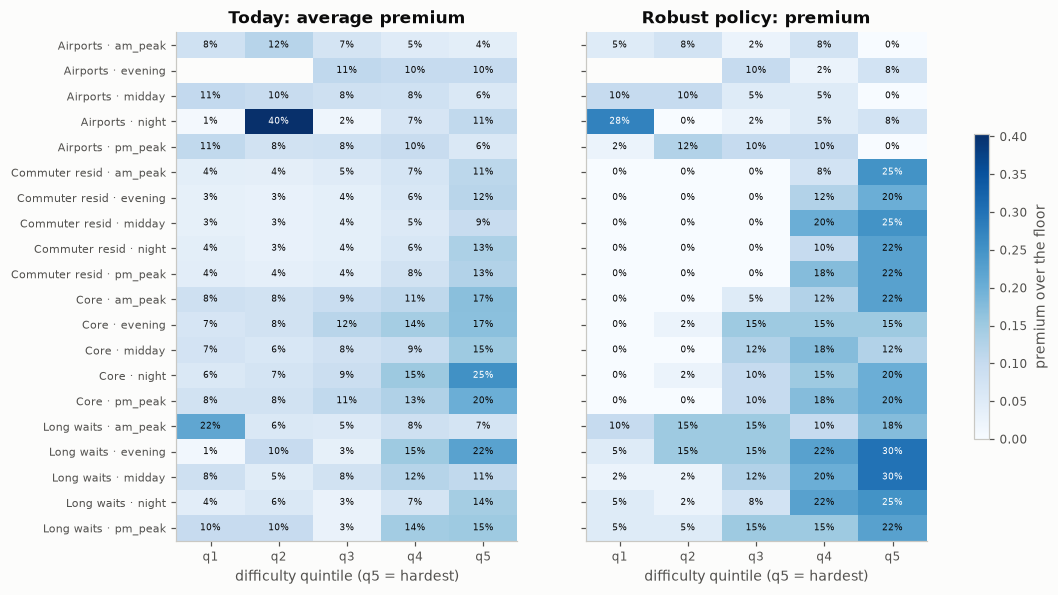

In [6]:
cells_view = fit_table.cells.assign(premium_point=policy.PREMIUMS[choice_point],
                                    premium_robust=policy.PREMIUMS[choice_robust])
sq_ratio = fit_df.groupby("cell").apply(lambda g: (g["offer_sq"].sum() / g["floor"].sum()) - 1, include_groups=False)
cells_view["premium_today"] = cells_view["cell"].map(sq_ratio)
cells_view["q"] = cells_view["cell"].str[-1].astype(int)
heat = cells_view.pivot_table(index=["cluster_name", "band"], columns="q", values="premium_robust")
heat_today = cells_view.pivot_table(index=["cluster_name", "band"], columns="q", values="premium_today")
fig, axes = plots.subplots(1, 2, figsize=(11, 6), sharey=True)
vmax = max(heat.max().max(), heat_today.max().max(), 0.3)
for ax, h, title in [(axes[0], heat_today, "Today: average premium"), (axes[1], heat, "Robust policy: premium")]:
    im = ax.imshow(h.to_numpy(), cmap=plots.SEQUENTIAL, vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(h.shape[1]), [f"q{c}" for c in h.columns])
    ax.set_yticks(range(h.shape[0]), [f"{c[:14]} · {b}" for c, b in h.index], fontsize=7)
    ax.set_xlabel("difficulty quintile (q5 = hardest)")
    ax.set_title(title)
    ax.grid(False)
    for (i, j), v in np.ndenumerate(h.to_numpy()):
        if np.isfinite(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=6,
                    color="white" if v > vmax * 0.6 else plots.INK)
fig.colorbar(im, ax=axes, shrink=0.6, label="premium over the floor")
data.savefig(fig, "06_premium_map")

## How stable is the recommendation?

Re-solve the point problem under 10 individual posterior draws. If the recommended premium for a
cell jumps around between plausible worlds, the data doesn't support a confident cell-level choice.

In [7]:
alt = []
for d in range(1, min(11, D + 1)):
    ch, _ = policy.optimize(fit_table, constraint_draws=[d], objective_draws=[d], time_limit=60)
    alt.append(policy.PREMIUMS[ch])
alt = np.array(alt)
spread = np.abs(alt - policy.PREMIUMS[choice_robust][None, :])
stability = {"same_as_robust_share": float((spread < 1e-9).mean()), "within_5pts_share": float((spread <= 0.05 + 1e-9).mean()),
             "mean_abs_diff_pts": float(100 * spread.mean())}
robust_in_draws = pd.DataFrame([policy.guardrails(fit_table, choice_robust, d) for d in range(1, D + 1)]).mean()
point_in_draws = pd.DataFrame([policy.guardrails(fit_table, choice_point, d) for d in range(1, D + 1)]).mean()
print("stability:", {k: round(v, 3) for k, v in stability.items()})
pd.DataFrame({"point policy": point_in_draws, "robust policy": robust_in_draws}).rename_axis("share of posterior draws where the guardrail holds")

HighsMipSolverData::transformNewIntegerFeasibleSolution tmpSolver.run();
HighsMipSolverData::transformNewIntegerFeasibleSolution tmpSolver.run();
HighsMipSolverData::transformNewIntegerFeasibleSolution tmpSolver.run();
HighsMipSolverData::transformNewIntegerFeasibleSolution tmpSolver.run();


stability: {'same_as_robust_share': 0.522, 'within_5pts_share': 0.898, 'mean_abs_diff_pts': 2.161}


,point policy,robust policy
share of posterior draws where the guardrail holds,,
C3_wait,0.2,1.0
C4_acceptance,0.5,1.0
C5_earnings,1.0,1.0


## Part B: dispatch simulation on real Brooklyn requests

**Calibration first.** The simulator's one free input that matters is how many drivers come online
each hour; the data has no driver records. It is calibrated so that, under today's pay, the
simulated mean wait in **each hour** matches the real mean wait of these requests, with batched
matching (a few rounds of
multiplicative updates: hours with too-long simulated waits get more drivers). Driver supply that
simply follows demand was tried first and could not reproduce the real pattern: real waits are
longest overnight, when drivers are scarcer *relative to* demand.

**Validation on what was not calibrated**: the 90th-percentile wait and the median wait by hour are
not targeted, so how close they come is a genuine check.

In [8]:
req_all = pd.read_parquet(data.interim_dir() / "sim_requests.parquet")
cents = con.sql("SELECT * FROM zones").df().set_index("zone")
cents["radius_mi"] = np.sqrt(cents["area_sq_mi"] / np.pi)
cents["in_area"] = cents["borough"] == "Brooklyn"
prev = con.sql("""SELECT zone, hour + INTERVAL 1 HOUR AS hour, wait_sum_sec / NULLIF(wait_n, 0) / 60 AS prev_wait_min
                  FROM zone_hour""").df()
req_all["hour_key"] = req_all["request_datetime"].dt.floor("h")
req_all = req_all.merge(prev, left_on=["PULocationID", "hour_key"], right_on=["zone", "hour"], how="left")
req_all["prev_wait_min"] = req_all["prev_wait_min"].fillna(req_all["prev_wait_min"].median())
req_all["cluster_name"] = req_all["PULocationID"].map(info["cluster_name"]).fillna("Sparse")
req_all["band"] = req_all["request_datetime"].dt.hour.map(config.BAND_OF_HOUR)
req_all = req_all[[(c, b) in seg_index for c, b in zip(req_all["cluster_name"], req_all["band"])]].copy()
req_all["minutes"] = req_all["trip_time"] / 60
req_all["fare"] = req_all["base_passenger_fare"]
from ridepay.pay import floor_pay  # noqa: E402

req_all["floor"] = floor_pay(req_all["trip_miles"], req_all["minutes"], req_all["request_datetime"], req_all["DOLocationID"])
req_all["offer_sq"] = np.maximum(req_all["driver_pay"], req_all["floor"])
req_all = req_all.join(simulate.difficulty_features(req_all, info))
req_all["seg"] = [seg_index[(c, b)] for c, b in zip(req_all["cluster_name"], req_all["band"])]
req_all["d_hat"] = req_all[accept.FEATURES].to_numpy() @ gamma_mean
req_all["q"] = np.searchsorted(edges, req_all["d_hat"]) + 1
req_all["cell"] = req_all["cluster_name"] + "|" + req_all["band"] + "|q" + req_all["q"].astype(str)
req_all["offer_policy"] = req_all["floor"] * (1 + req_all["cell"].map(robust_premium).fillna(0.0))
days = sorted(req_all["request_datetime"].dt.date.unique())
print(f"{len(req_all):,} requests on {[str(d) for d in days]}")

387,639 requests on ['2025-06-10', '2025-06-14']


In [9]:
def day_inputs(day, seed=0):
    r = req_all[req_all["request_datetime"].dt.date == day].sort_values("request_datetime").reset_index(drop=True)
    start = pd.Timestamp(day)
    r["t_sec"] = (r["request_datetime"] - start).dt.total_seconds()
    hourly = r.groupby(r["request_datetime"].dt.hour).size().reindex(range(24), fill_value=0).to_numpy()
    sp = (r.groupby(r["request_datetime"].dt.hour).apply(lambda g: g["trip_miles"].sum() / (g["trip_time"].sum() / 3600),
                                                          include_groups=False).reindex(range(24)).ffill().bfill().to_numpy())
    idx = list(zip(r["cluster_name"], r["band"]))
    a, b = truth_tab.loc[idx, "a"].to_numpy(), truth_tab.loc[idx, "beta"].to_numpy()
    u = np.random.default_rng(100 + seed).normal(0, simulate.U_SD, len(r))   # same u for every policy (common random numbers)
    d_obs = simulate.observed_difficulty(r)

    def p_of(offer):
        return expit(a - d_obs - u + b * np.log(offer / r["floor"].to_numpy()))

    return r, hourly, sp, p_of


def simulate_day(day, offer_col, matching, supply, seed=0, batch_sec=30):
    """One simulated day. ``supply``: 24 multipliers on driver arrivals (0.25 per request in that hour)."""
    r, hourly, sp, p_of = day_inputs(day, seed)
    offer = r[offer_col].to_numpy()
    cfg = dispatch.SimConfig(matching=matching, supply_scale=1.0, seed=seed, batch_sec=batch_sec)
    res = dispatch.run(r, p_of(offer), offer, cents, hourly * 0.25 * np.asarray(supply), sp, cfg)
    out = dispatch.summarize(r, res, r["fare"].to_numpy(), offer, policy.CANCEL_COST)
    hours = r["request_datetime"].dt.hour.to_numpy()
    out["wait_by_hour"] = pd.Series(res["wait_sec"] / 60).groupby(hours).mean().reindex(range(24)).to_numpy()
    return out


real = {d: req_all[(req_all["request_datetime"].dt.date == d) & req_all["wait_valid"]] for d in days}
real_hourly = {d: (real[d].groupby(real[d]["request_datetime"].dt.hour)["wait_sec"].mean().reindex(range(24)) / 60).to_numpy()
               for d in days}
target = {d: (real[d]["wait_sec"] / 60).mean() for d in days}
t0 = time.time()
calib, calib_path = {}, []
for d in days:
    supply = np.full(24, 0.5)
    for it in range(3 if FAST else 6):
        sim_h = simulate_day(d, "offer_sq", "batch", supply)["wait_by_hour"]
        ratio = np.where(np.isfinite(sim_h / real_hourly[d]), sim_h / real_hourly[d], 1.0)
        calib_path.append({"day": str(d), "iteration": it, "mean_abs_gap_min": float(np.nanmean(np.abs(sim_h - real_hourly[d])))})
        # too long a wait -> more drivers that hour; smoothed with the neighbouring hours
        step = np.clip(ratio, 0.5, 2.0) ** 0.8
        step = (np.roll(step, 1) + 2 * step + np.roll(step, -1)) / 4
        supply = np.clip(supply * step, 0.05, 5.0)
    calib[d] = supply
print(pd.DataFrame(calib_path).pivot(index="iteration", columns="day", values="mean_abs_gap_min").round(3),
      f"\ncalibrated in {time.time() - t0:.0f}s")

day        2025-06-10  2025-06-14
iteration                        
0               2.899       2.818
1               1.316       0.994
2               0.863       0.683
3               0.498       0.664
4               0.438       0.590
5               0.340       0.566 
calibrated in 187s


,real mean,sim mean,real median (not targeted),sim median,real p90 (not targeted),sim p90,hourly corr
day,,,,,,,
2025-06-10,4.86,4.84,4.20,3.87,8.27,9.35,0.83
2025-06-14,5.39,5.30,4.68,3.91,9.22,10.90,0.58


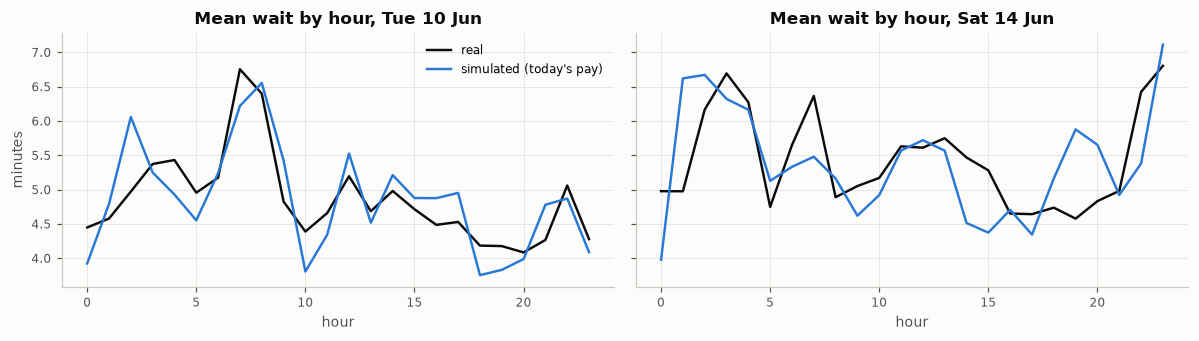

In [10]:
val = {d: simulate_day(d, "offer_sq", "batch", calib[d]) for d in days}
fig, axes = plots.subplots(1, len(days), figsize=(11, 3.2), sharey=True)
check = []
for ax, d in zip(np.atleast_1d(axes), days):
    ax.plot(range(24), real_hourly[d], color=plots.INK, lw=1.6, label="real")
    ax.plot(range(24), val[d]["wait_by_hour"], color=plots.SERIES[0], lw=1.6, label="simulated (today's pay)")
    ax.set(title=f"Mean wait by hour, {pd.Timestamp(d):%a %d %b}", xlabel="hour")
    w = real[d]["wait_sec"] / 60
    check.append({"day": str(d), "real mean": w.mean(), "sim mean": val[d]["wait_mean_min"],
                  "real median (not targeted)": w.median(), "sim median": val[d]["wait_p50_min"],
                  "real p90 (not targeted)": w.quantile(0.9), "sim p90": val[d]["wait_p90_min"],
                  "hourly corr": float(np.corrcoef(real_hourly[d], val[d]["wait_by_hour"])[0, 1])})
np.atleast_1d(axes)[0].legend()
np.atleast_1d(axes)[0].set_ylabel("minutes")
fig.tight_layout()
data.savefig(fig, "06_sim_validation")
check = pd.DataFrame(check).set_index("day")
corr = check["hourly corr"].to_dict()
check.round(2)

**The experiments**: today's pay vs the robust policy, crossed with greedy vs batched matching, on
both days and three random seeds each (the seed changes driver arrivals and decisions; the riders'
unobserved difficulty is held fixed across policies so comparisons are paired).

In [11]:
t0 = time.time()
runs = []
for d in days:
    for seed in range(2 if FAST else 3):
        for offer_col, pname in [("offer_sq", "Today's pay"), ("offer_policy", "Robust policy")]:
            for matching in ["greedy", "batch"]:
                s = simulate_day(d, offer_col, matching, calib[d], seed=seed)
                s.pop("wait_by_hour")
                runs.append({"day": str(d), "seed": seed, "pay": pname, "matching": matching, **s})
runs = pd.DataFrame(runs)
print(f"{len(runs)} runs in {time.time() - t0:.0f}s")
KPIS = ["completion", "first_offer_acceptance", "wait_mean_min", "wait_p90_min", "pickup_mean_min",
        "margin_per_request", "pay_per_trip", "earnings_per_online_hour"]
sim_table = runs.groupby(["pay", "matching"])[KPIS].mean()
sim_table.round(3)

24 runs in 807s


completion  first_offer_acceptance  wait_mean_min  \
pay           matching                                                      
Robust policy batch          0.938                   0.717          4.916   
              greedy         0.952                   0.716         12.183   
Today's pay   batch          0.931                   0.703          5.061   
              greedy         0.938                   0.703         14.433   

                        wait_p90_min  pickup_mean_min  margin_per_request  \
pay           matching                                                      
Robust policy batch            9.753            3.461               2.965   
              greedy          23.096            4.904               3.108   
Today's pay   batch           10.115            3.413               3.077   
              greedy          24.065            4.950               3.168   

                        pay_per_trip  earnings_per_online_hour  
pay           matching                                          
Robust policy batch           18.809                    57.174  
              greedy          18.830                    54.638  
Today's pay   batch           18.638                    56.772  
              greedy          18.686                    54.031

In [12]:
paired = runs[runs["matching"] == "batch"].set_index(["day", "seed", "matching", "pay"])[KPIS].unstack("pay")
diff_pay = (paired.xs("Robust policy", axis=1, level=1) - paired.xs("Today's pay", axis=1, level=1))
paired_m = runs.set_index(["day", "seed", "pay", "matching"])[KPIS].unstack("matching")
diff_match = paired_m.xs("batch", axis=1, level=1) - paired_m.xs("greedy", axis=1, level=1)


def mean_ci(x):
    x = np.asarray(x, float)
    se = x.std(ddof=1) / np.sqrt(len(x))
    return pd.Series({"mean": x.mean(), "lo": x.mean() - 2.0 * se, "hi": x.mean() + 2.0 * se})


effects = pd.concat({"Robust policy − today's pay": diff_pay.apply(mean_ci).T,
                     "Batched − greedy matching": diff_match.apply(mean_ci).T})
effects.round(3)

mean      lo      hi
Robust policy − today's pay completion                 0.007  -0.001   0.015
                            first_offer_acceptance     0.014   0.013   0.015
                            wait_mean_min             -0.146  -0.266  -0.025
                            wait_p90_min              -0.361  -0.674  -0.048
                            pickup_mean_min            0.048  -0.098   0.194
                            margin_per_request        -0.113  -0.137  -0.088
                            pay_per_trip               0.171   0.103   0.239
                            earnings_per_online_hour   0.401   0.213   0.590
Batched − greedy matching   completion                -0.010  -0.014  -0.007
                            first_offer_acceptance     0.000  -0.000   0.001
                            wait_mean_min             -8.320 -11.037  -5.603
                            wait_p90_min             -13.646 -14.669 -12.624
                            pickup_mean_min           -1.490  -1.763  -1.217
                            margin_per_request        -0.117  -0.141  -0.093
                            pay_per_trip              -0.035  -0.053  -0.016
                            earnings_per_online_hour   2.638   1.974   3.303

In [13]:
record = {
    "fit_months": FIT, "held_months": HELD, "cells": len(fit_table.cells), "premium_options": policy.PREMIUMS.tolist(),
    "assumptions": {"reoffer_sec": policy.REOFFER_SEC, "cancel_per_decline": policy.CANCEL_PER_DECLINE,
                    "cancel_cost": policy.CANCEL_COST, "earnings_floor": policy.EARNINGS_FLOOR},
    "fit_summary": fit_summary.round(5).to_dict(orient="index"),
    "held_summary": held_summary.round(5).to_dict(orient="index"),
    "by_borough": by_borough.round(5).reset_index().to_dict(orient="records"),
    "stability": stability, "guardrails_in_draws": {"point": point_in_draws.to_dict(), "robust": robust_in_draws.to_dict()},
    "premium_table": cells_view.round(4).to_dict(orient="records"),
    "sim": {"days": [str(d) for d in days], "supply_profile": {str(k): np.round(v, 4).tolist() for k, v in calib.items()},
            "real_mean_wait": {str(k): v for k, v in target.items()}, "hourly_corr": corr,
            "validation": check.round(4).reset_index().to_dict(orient="records"),
            "table": sim_table.round(5).reset_index().to_dict(orient="records"),
            "effects": effects.round(5).reset_index().rename(columns={"level_0": "comparison", "level_1": "kpi"}).to_dict(orient="records")},
}
_ = write_metrics("06_policy_simulation", record, SOURCE)
policy_out = cells_view[["cell", "cluster_name", "band", "q", "premium_robust", "premium_point", "premium_today"]]
_ = data.save_table(policy_out, "pay_policy")
_ = data.save_table(pd.DataFrame({"edge": edges}), "difficulty_edges")

## Verdict

In [14]:
H = held_summary
rob, today = H.loc["Optimized (robust)"], H.loc["Today"]
ep = effects.loc["Robust policy − today's pay"]
em = effects.loc["Batched − greedy matching"]
all_ok = bool(rob[["C3_wait", "C4_acceptance", "C5_earnings"]].all())
show_verdict(
    "Verdict: phase 6, pay policy and simulation",
    [
        f"**Held out (Apr–Jun 2025), scored against the truth, the robust policy raises margin per request by "
        f"{rob['margin_vs_today_pct']:+.1f}%** (${today['margin_per_request']:.2f} → ${rob['margin_per_request']:.2f}) "
        f"with first-offer acceptance {today['first_offer_acceptance']:.1%} → {rob['first_offer_acceptance']:.1%} and pay per "
        f"trip ${today['pay_per_trip']:.2f} → ${rob['pay_per_trip']:.2f}; guardrails C3–C5 "
        f"{'all hold' if all_ok else 'do NOT all hold: ' + str(rob[['C3_wait', 'C4_acceptance', 'C5_earnings']].to_dict())}.",
        f"**Floor-only is a trap**: it pays least but {'breaks' if not H.loc['Floor only', ['C3_wait', 'C4_acceptance', 'C5_earnings']].all() else 'keeps'} "
        f"the guardrails (acceptance {H.loc['Floor only', 'first_offer_acceptance']:.1%}, margin "
        f"{H.loc['Floor only', 'margin_vs_today_pct']:+.1f}% once cancellations are counted).",
        f"**Robustness has a price and a payoff**: the point policy (best guess only) meets the wait guardrail in "
        f"{point_in_draws['C3_wait']:.0%}, acceptance in {point_in_draws['C4_acceptance']:.0%} and earnings in "
        f"{point_in_draws['C5_earnings']:.0%} of posterior draws; the robust policy meets all three in "
        f"{robust_in_draws.min():.0%} of them, for {H.loc['Optimized (point)', 'margin_vs_today_pct'] - rob['margin_vs_today_pct']:.1f} "
        f"points of margin. Cell premiums differ by {stability['mean_abs_diff_pts']:.1f} points on average across plausible "
        "worlds, so trust the policy at segment level, not cell by cell.",
        f"**In the dispatch simulation** (real Brooklyn requests; driver supply calibrated hour by hour to real waits; "
        f"untargeted p90 wait {check['sim p90'].mean():.1f} min simulated vs {check['real p90 (not targeted)'].mean():.1f} real), "
        f"the policy raises completion by {ep.loc['completion', 'mean']:+.1%} and first-offer acceptance by "
        f"{ep.loc['first_offer_acceptance', 'mean']:+.1%}, changes mean wait by {ep.loc['wait_mean_min', 'mean']:+.2f} min and "
        f"margin per request by {ep.loc['margin_per_request', 'mean']:+.2f} dollars. That matches the expected-value model for "
        f"Brooklyn ({by_borough.loc['Brooklyn', 'margin change']:+.2f} per request): the policy moves premium from Manhattan "
        f"({by_borough.loc['Manhattan', 'margin change']:+.2f}) to the outer boroughs, buying service there.",
        f"**Matching matters as much as pay.** Batching (one assignment problem every 30 s) cuts mean wait by "
        f"{-em.loc['wait_mean_min', 'mean']:.1f} min vs greedy nearest-driver, but by minimizing total pickup time it leaves "
        f"isolated requests waiting until some riders give up (completion {em.loc['completion', 'mean']:+.1%}). The next step "
        "is a cost that also values how long a request has waited (tried with a simple age weight: at today's tight supply it "
        "sent drivers on long pickups and made waits worse, so it needs tuning, not a guess).",
    ],
    "phase 7: package the policy as a quote service (FastAPI, Docker, CI/CD).",
)

### Verdict: phase 6, pay policy and simulation

1. **Held out (Apr–Jun 2025), scored against the truth, the robust policy raises margin per request by +2.8%** (\$5.76 → \$5.92) with first-offer acceptance 70.6% → 71.2% and pay per trip \$21.48 → \$21.32; guardrails C3–C5 all hold.
2. **Floor-only is a trap**: it pays least but breaks the guardrails (acceptance 64.8%, margin +26.7% once cancellations are counted).
3. **Robustness has a price and a payoff**: the point policy (best guess only) meets the wait guardrail in 20%, acceptance in 50% and earnings in 100% of posterior draws; the robust policy meets all three in 100% of them, for 0.4 points of margin. Cell premiums differ by 2.2 points on average across plausible worlds, so trust the policy at segment level, not cell by cell.
4. **In the dispatch simulation** (real Brooklyn requests; driver supply calibrated hour by hour to real waits; untargeted p90 wait 10.1 min simulated vs 8.7 real), the policy raises completion by +0.7% and first-offer acceptance by +1.4%, changes mean wait by -0.15 min and margin per request by -0.11 dollars. That matches the expected-value model for Brooklyn (-0.18 per request): the policy moves premium from Manhattan (+0.81) to the outer boroughs, buying service there.
5. **Matching matters as much as pay.** Batching (one assignment problem every 30 s) cuts mean wait by 8.3 min vs greedy nearest-driver, but by minimizing total pickup time it leaves isolated requests waiting until some riders give up (completion -1.0%). The next step is a cost that also values how long a request has waited (tried with a simple age weight: at today's tight supply it sent drivers on long pickups and made waits worse, so it needs tuning, not a guess).

**Next:** phase 7: package the policy as a quote service (FastAPI, Docker, CI/CD).